# Sunday Project: Data Quality, Insights & CSV Operations
**AI Engineering Bootcamp | Module 02**

This notebook has two parts:
- **Part A** (70 marks): load, inspect, clean, analyze and chart `sales_raw.csv`, then save `cleaned_sales.csv`.
- **Part B** (30 marks): edit `cleaned_sales.csv` and save the result as `sales_updated.csv`.

All paths are relative, so keep this notebook in the same folder as `sales_raw.csv` (in Colab, upload the file to the session first).

# Part A: Data Quality & Basic Insights

## 1. Load and inspect

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Define file names
RAW_PATH = "sales_raw.csv"
CLEAN_PATH = "cleaned_sales.csv"

# Read original CSV file
df_raw = pd.read_csv(RAW_PATH)

# Display first five rows
df_raw.head()

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


In [2]:
print("Shape (rows, columns):", df_raw.shape)
print("\nColumn names:", list(df_raw.columns))
print("\nData types:")
print(df_raw.dtypes)

Shape (rows, columns): (21, 6)

Column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data types:
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object


In [3]:
print("Missing values per column:")
print(df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())

Missing values per column:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate rows: 1


In [4]:
# Look at the exact text values, because the problems below are hidden in them
print(df_raw["region"].unique())
print(df_raw["category"].unique())
print(df_raw[pd.to_numeric(df_raw["unit_price"], errors="coerce").isna()])

<StringArray>
['North', 'South', 'East', 'SOUTH', 'West', nan]
Length: 6, dtype: str
<StringArray>
[' food ', 'Books', 'Food', 'Stationery', 'books', ' food']
Length: 6, dtype: str
    transaction_id  sale_date region    category  quantity unit_price
9             1010  10/5/2026  South  Stationery       2.0        NaN
10            1011  10/6/2026   East        Food       2.0    invalid


**What the inspection shows**
- `unit_price` was read as text (`object`/`str`) instead of a number, because row 1011 contains the word `invalid`.
- `quantity` is a float because of a missing value; one quantity is negative (row 1013).
- `region` and `category` have extra spaces and mixed case (` food `, `SOUTH`, `books`).
- `sale_date` has one unparseable value (`invalid-date`, row 1014).
- One region is missing (row 1018), one price is missing (row 1010), and row 1003 is duplicated at the end of the file.
- Row 1016 has a unit price of 10,000 for Stationery, whose other prices are 40 to 60. This is almost certainly a typo.

## 2. Clean the dataset

In [5]:
df = df_raw.copy()          # work on a copy; df_raw stays untouched
rows_before = len(df)

# --- 2a. Text: trim spaces and standardize case ---
for col in ["region", "category"]:
    df[col] = df[col].str.strip().str.title()

# --- 2b. Types: convert to numbers/dates; bad values become NaN/NaT instead of crashing ---
df["quantity"]   = pd.to_numeric(df["quantity"], errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["sale_date"]  = pd.to_datetime(df["sale_date"], format="%m/%d/%Y", errors="coerce")

print(df["region"].unique(), df["category"].unique())

<StringArray>
['North', 'South', 'East', 'West', nan]
Length: 5, dtype: str <StringArray>
['Food', 'Books', 'Stationery']
Length: 3, dtype: str


In [6]:
# --- 2c. Duplicates: keep the first copy of an identical row ---
dups = df.duplicated().sum()
df = df.drop_duplicates()
print("Duplicate rows removed:", dups)

# --- 2d. Missing region: label as 'Unknown' (keeps a valid sale instead of losing it) ---
df["region"] = df["region"].fillna("Unknown")

# --- 2e. Invalid numbers: drop rows we cannot calculate revenue for ---
# Missing/non-numeric quantity or price, or quantity/price <= 0
bad_numbers = df["quantity"].isna() | df["unit_price"].isna() | (df["quantity"] <= 0) | (df["unit_price"] <= 0)
print("Rows with missing/invalid quantity or price:")
print(df[bad_numbers][["transaction_id", "quantity", "unit_price"]])
df = df[~bad_numbers]

# --- 2f. Price outliers: a price over 10x its category median is treated as a typo ---
cat_median = df.groupby("category")["unit_price"].transform("median")
outlier = df["unit_price"] > 10 * cat_median
print("\nPrice outliers:")
print(df[outlier][["transaction_id", "category", "unit_price"]])
df = df[~outlier].reset_index(drop=True)

df["quantity"] = df["quantity"].astype(int)

Duplicate rows removed: 1
Rows with missing/invalid quantity or price:
    transaction_id  quantity  unit_price
5             1006       NaN       130.0
9             1010       2.0         NaN
10            1011       2.0         NaN
12            1013      -2.0       130.0

Price outliers:
    transaction_id    category  unit_price
15            1016  Stationery     10000.0


In [7]:
rows_after = len(df)
print(f"Rows before cleaning: {rows_before}")
print(f"Rows after cleaning:  {rows_after}")
print(f"Rows removed:         {rows_before - rows_after}")
print("\nRemaining missing values:")
print(df.isna().sum())

Rows before cleaning: 21
Rows after cleaning:  15
Rows removed:         6

Remaining missing values:
transaction_id    0
sale_date         1
region            0
category          0
quantity          0
unit_price        0
dtype: int64


**Cleaning rules and why**

| Problem | Rows | Rule | Reason |
|---|---|---|---|
| Extra spaces / mixed case in `region`, `category` | several | `strip()` + `title()` | `food`, ` Food`, `FOOD` must group together |
| Duplicate row | 1003 (second copy) | `drop_duplicates()` | An identical repeat would double-count revenue |
| Missing quantity | 1006 | Drop | Revenue cannot be calculated, and guessing a quantity would invent sales |
| Missing price | 1010 | Drop | Same reason |
| Non-numeric price (`invalid`) | 1011 | Drop | Same reason |
| Negative quantity | 1013 | Drop | A sale cannot have negative units (it looks like a data-entry error or an unlabeled return) |
| Price outlier (10,000 vs 40-60) | 1016 | Drop (price > 10x category median) | Would dominate every total and distort the charts |
| Missing region | 1018 | Fill with `Unknown` | Quantity and price are valid, so the revenue is real; only the label is missing |
| Invalid date | 1014 | Keep, date left blank | The date is not used in revenue analysis and the row is otherwise valid |

## 3. Calculate and analyze

In [8]:
df["revenue"] = df["quantity"] * df["unit_price"]
df.head()

,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,2026-10-01,North,Food,2,120.0,240.0
1,1002,2026-10-01,South,Books,1,250.0,250.0
2,1003,2026-10-02,North,Food,3,110.0,330.0
3,1004,2026-10-02,East,Stationery,4,50.0,200.0
4,1005,2026-10-03,South,Books,2,250.0,500.0


In [9]:
# Group by region and by category
region_summary = (df.groupby("region")["revenue"].sum()
                    .sort_values(ascending=False)
                    .reset_index(name="total_revenue"))
category_summary = (df.groupby("category")
                      .agg(total_revenue=("revenue", "sum"),
                           transactions=("transaction_id", "count"),
                           avg_revenue_per_sale=("revenue", "mean"))
                      .sort_values("total_revenue", ascending=False)
                      .round(2).reset_index())
print(region_summary, "\n")
print(category_summary)
print("\nTotal revenue:", df["revenue"].sum())

    region  total_revenue
0    North         1470.0
1     West         1130.0
2    South         1035.0
3     East          740.0
4  Unknown          400.0 

     category  total_revenue  transactions  avg_revenue_per_sale
0       Books         2370.0             6                395.00
1        Food         1945.0             6                324.17
2  Stationery          460.0             3                153.33

Total revenue: 4775.0


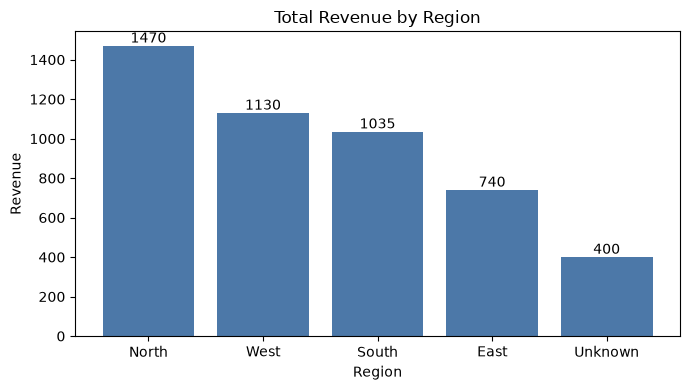

In [10]:
# Chart 1: revenue by region
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(region_summary["region"], region_summary["total_revenue"], color="#4C78A8")
ax.bar_label(bars, fmt="%.0f")
ax.set_title("Total Revenue by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.savefig("chart_revenue_by_region.png", dpi=150)
plt.show()

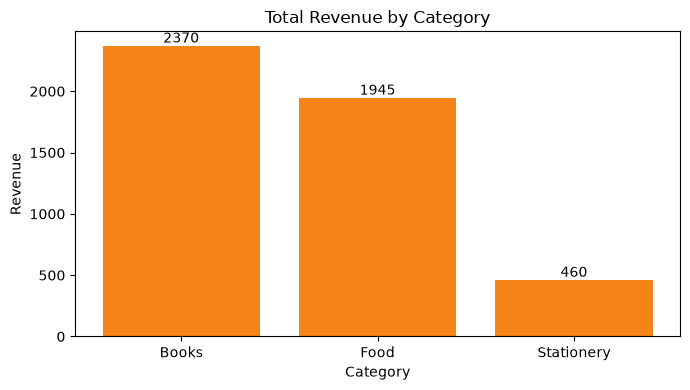

In [11]:
# Chart 2: revenue by category
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(category_summary["category"], category_summary["total_revenue"], color="#F58518")
ax.bar_label(bars, fmt="%.0f")
ax.set_title("Total Revenue by Category")
ax.set_xlabel("Category")
ax.set_ylabel("Revenue")
plt.tight_layout()
plt.savefig("chart_revenue_by_category.png", dpi=150)
plt.show()

### Findings
1. **Books drive about half of all revenue.** Books brought in 2,370 of the 4,775 total (about 49.6%) from just 6 sales, giving the highest average sale (395). Food has the same number of sales (6) but only 1,945 revenue (avg about 324), and Stationery is smallest at 460 (about 9.6%) across 3 sales. Chart: *Total Revenue by Category*.
2. **North is the strongest region and East the weakest of the known regions.** North generated 1,470 (about 30.8% of total), followed by West at 1,130 and South at 1,035, while East trails at 740. A further 400 comes from a sale with no region recorded (`Unknown`), so fixing that missing label could change the ranking gap between regions. Chart: *Total Revenue by Region*.

*Caveat: after cleaning, only 15 transactions remain, so these patterns are indicative rather than conclusive.*

## 4. Save the result

In [12]:
df.to_csv(CLEAN_PATH, index=False)
print("Saved", CLEAN_PATH, "with", len(df), "rows")

Saved cleaned_sales.csv with 15 rows


# Part B: CSV File Handling & Manipulation

## 1. Read and add a column

In [13]:
df_b = pd.read_csv("cleaned_sales.csv")
df_b["tax_amount"] = df_b["revenue"] * 0.05
df_b.head()

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2,250.0,500.0,25.0


## 2. Update and remove

In [14]:
# Increase Books unit_price by 10% using .loc, then recalculate revenue and tax
is_books = df_b["category"] == "Books"
df_b.loc[is_books, "unit_price"] = (df_b.loc[is_books, "unit_price"] * 1.10).round(2)
df_b["revenue"]    = (df_b["quantity"] * df_b["unit_price"]).round(2)
df_b["tax_amount"] = (df_b["revenue"] * 0.05).round(2)
df_b[is_books]

,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
1,1002,2026-10-01,South,Books,1,275.0,275.0,13.75
4,1005,2026-10-03,South,Books,2,275.0,550.0,27.50
6,1008,2026-10-04,East,Books,1,330.0,330.0,16.50
8,1012,2026-10-06,North,Books,1,352.0,352.0,17.60
9,1014,NaN,West,Books,2,330.0,660.0,33.00
12,1018,2026-10-09,Unknown,Books,2,220.0,440.0,22.00


In [15]:
# Remove one row using an existing transaction_id
remove_id = 1019
assert remove_id in df_b["transaction_id"].values, "transaction_id not found"
rows_before_b = len(df_b)
df_b = df_b[df_b["transaction_id"] != remove_id].reset_index(drop=True)
print(f"Removed transaction {remove_id}: {rows_before_b} -> {len(df_b)} rows")

Removed transaction 1019: 15 -> 14 rows


In [16]:
# Temporary column, then remove it with drop(columns=...)
df_b["review_status"] = "pending"
print("With temp column:", list(df_b.columns))
df_b = df_b.drop(columns=["review_status"])
print("After drop:      ", list(df_b.columns))

With temp column: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount', 'review_status']
After drop:       ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']


## 3. Save and verify

In [17]:
df_b.to_csv("sales_updated.csv", index=False)

verify = pd.read_csv("sales_updated.csv")
print(verify.head())
print("\nFinal columns:", list(verify.columns))
print("Shape:", verify.shape)

   transaction_id   sale_date region    category  quantity  unit_price  \
0            1001  2026-10-01  North        Food         2       120.0   
1            1002  2026-10-01  South       Books         1       275.0   
2            1003  2026-10-02  North        Food         3       110.0   
3            1004  2026-10-02   East  Stationery         4        50.0   
4            1005  2026-10-03  South       Books         2       275.0   

   revenue  tax_amount  
0    240.0       12.00  
1    275.0       13.75  
2    330.0       16.50  
3    200.0       10.00  
4    550.0       27.50  

Final columns: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
Shape: (14, 8)
